# Category-Conditioned Sketch Generation with Variational Autoencoders

**Author:** Ashwin Parthasarathy

This project develops a sketch generator in PyTorch using human-drawn examples from Google Quick, Draw!. Development begins with a one-category feasibility experiment before expanding to category-conditioned generation.

Evaluation will examine randomly generated samples, recognizability, diversity, and similarity to training examples. Model choices and quality claims will be grounded in the experiments recorded in this notebook.

## 1. Environment and reproducibility

In [1]:
import hashlib
import json
import random
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
PROJECT_ROOT = Path.cwd()
SEED = 42

In [3]:
assert (PROJECT_ROOT / ".git").is_dir(), (
    "Open this notebook from the sketch-generation-vae repository root."
)

# Seed the random generators used for data selection and model training.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)

Project: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae
Python: 3.14.0
Executable: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/.venv/bin/python
PyTorch: 2.15.0
Device: mps


## 2. Dataset acquisition and initial inspection

The project uses human-drawn sketches from [Google Quick, Draw!](https://github.com/googlecreativelab/quickdraw-dataset), released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

The initial feasibility experiment uses the apple category. The supplied NumPy file contains flattened 28 × 28 grayscale images rendered from simplified human drawings. Rasterization is preprocessing; these are not AI-generated training examples.

The bitmap file does not retain contributor identifiers, country information, or recognition flags. Consequently, it does not support contributor-independent splitting or demographic analysis.

This section inspects the downloaded data. Training, validation, and test partitions will be created separately before model development.

In [4]:
DATA_URL = (
    "https://storage.googleapis.com/"
    "quickdraw_dataset/full/numpy_bitmap/apple.npy"
)
DATA_PATH = PROJECT_ROOT / "data/raw/apple.npy"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    temporary_path = DATA_PATH.with_suffix(".npy.partial")
    print("Downloading apple sketches...", flush=True)

    # Publish the file only after the download finishes.
    with urlopen(DATA_URL, timeout=60) as response:
        expected_bytes = response.headers.get("Content-Length")
        with temporary_path.open("wb") as destination:
            shutil.copyfileobj(response, destination)

    if expected_bytes is not None:
        assert temporary_path.stat().st_size == int(expected_bytes), (
            "Download size mismatch; do not use this file."
        )

    temporary_path.replace(DATA_PATH)

In [5]:
# Memory mapping avoids loading the entire category into RAM.
apple_images = np.load(DATA_PATH, mmap_mode="r", allow_pickle=False)

assert apple_images.ndim == 2 and apple_images.shape[1] == 28 * 28
assert apple_images.dtype == np.uint8
assert len(apple_images) >= 30000

In [6]:
file_hash = hashlib.sha256()
with DATA_PATH.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        file_hash.update(chunk)

source_record = {
    "dataset": "Google Quick, Draw!",
    "category": "apple",
    "url": DATA_URL,
    "license": "CC BY 4.0",
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "sha256": file_hash.hexdigest(),
    "bytes": DATA_PATH.stat().st_size,
    "shape": list(apple_images.shape),
    "dtype": str(apple_images.dtype)
}

(PROJECT_ROOT / "reports").mkdir(exist_ok=True)
with (PROJECT_ROOT / "reports/apple_source.json").open("w") as handle:
    json.dump(source_record, handle, indent=2)

print("Images:", len(apple_images))
print("Image dimensions: 28 × 28")
print("Data type:", apple_images.dtype)
print(f"File size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
print("SHA-256:", source_record["sha256"])

Images: 144722
Image dimensions: 28 × 28
Data type: uint8
File size: 108.2 MiB
SHA-256: a70df0030c146cfe4aa9a17aa2a320d5f64ac166fdc3d2cfb439b8322fd8bb0d


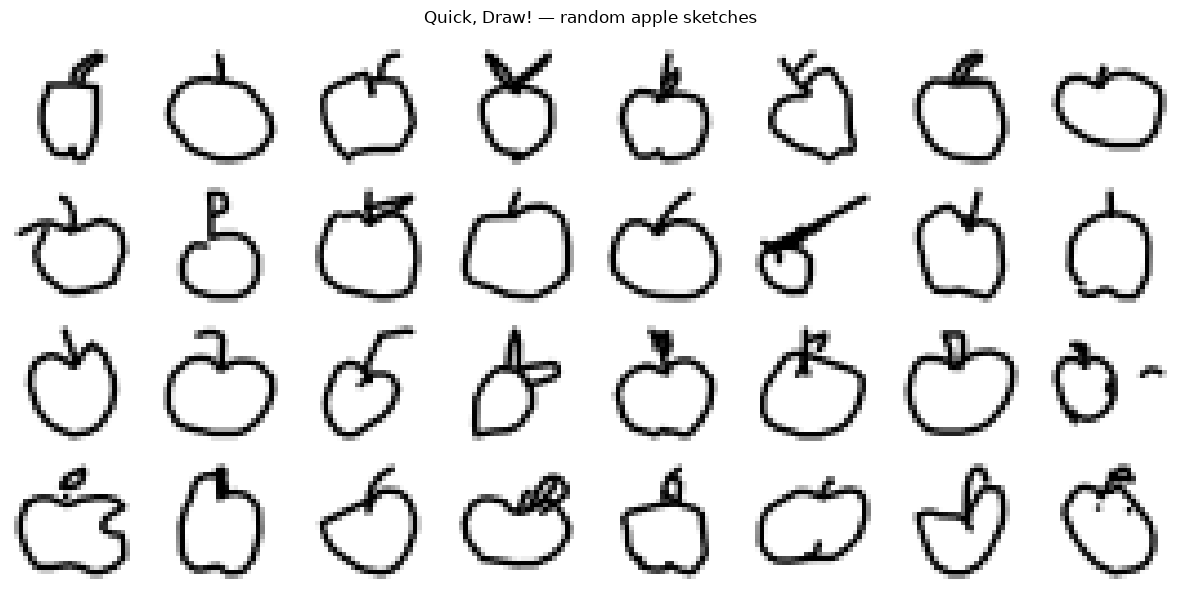

In [7]:
preview_rng = np.random.default_rng(SEED)
preview_indices = preview_rng.choice(len(apple_images), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for axis, index in zip(axes.flat, preview_indices):
    axis.imshow(
        apple_images[index].reshape(28, 28),
        cmap="gray_r",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axis.axis("off")

fig.suptitle("Quick, Draw! — random apple sketches")
fig.tight_layout()
plt.savefig("figures/random_apple_sketches.png")
plt.show()
plt.close(fig)

## 3. Automated audit and reproducible data splits

Blank images and exact pixel duplicates are excluded automatically. Duplicate detection uses SHA-256 hashes of the original 28 × 28 pixel arrays; it does not detect near duplicates or identify individual contributors.

A seeded random sample of 30,000 unique, nonblank sketches forms the feasibility dataset: 24,000 training, 3,000 validation, and 3,000 test images.

The manifest records each image's row index in the downloaded NumPy file and its pixel hash. Combined with the source file's SHA-256 checksum, this allows the same selection to be reconstructed without committing the raw images.

Validation guides model development. Test images remain unused until the final evaluation. No subjective filtering is applied to drawing quality.

In [8]:
# Audit all images before selecting the experiment subset.
unique_rows = []
seen_hashes = set()
blank_count = 0
duplicate_count = 0

for source_index in range(len(apple_images)):
    pixels = apple_images[source_index]

    # Quick, Draw! bitmaps use zero for background and larger values for ink.
    if not np.any(pixels):
        blank_count += 1
        continue

    pixel_hash = hashlib.sha256(pixels.tobytes()).hexdigest()

    if pixel_hash in seen_hashes:
        duplicate_count += 1
        continue

    seen_hashes.add(pixel_hash)
    unique_rows.append({
        "source_index": source_index,
        "category": "apple",
        "pixel_sha256": pixel_hash,
    })

unique_inventory = pd.DataFrame(unique_rows)
assert len(unique_inventory) >= 30000

# Shuffle once, reproducibly, then assign nonoverlapping partitions.
split_rng = np.random.default_rng(SEED)
selected_positions = split_rng.choice(len(unique_inventory), size=30000, replace=False)

apple_manifest = unique_inventory.iloc[selected_positions].reset_index(drop=True)

apple_manifest["split"] = (
    ["train"] * 24_000
    + ["validation"] * 3000
    + ["test"] * 3000
)

assert apple_manifest["source_index"].is_unique
assert apple_manifest["pixel_sha256"].is_unique

processed_dir = PROJECT_ROOT / "data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
apple_manifest.to_csv(processed_dir / "apple_split_manifest.csv", index=False)

audit_record = {
    "source_file_sha256": source_record["sha256"],
    "source_images": len(apple_images),
    "blank_images_excluded": blank_count,
    "duplicate_images_excluded": duplicate_count,
    "unique_nonblank_images": len(unique_inventory),
    "selected_images": len(apple_manifest),
    "seed": SEED,
    "split_counts": {
        split: int(count)
        for split, count in apple_manifest["split"].value_counts().items()
    }
}

with (PROJECT_ROOT / "reports/apple_data_audit.json").open("w") as handle:
    json.dump(audit_record, handle, indent=2)

print("Blank images excluded:", blank_count)
print("Exact duplicate images excluded:", duplicate_count)
print("Unique nonblank images:", len(unique_inventory))
print("\nSelected split counts:")
print(apple_manifest["split"].value_counts())

# Release the temporary audit structures; keep the selected manifest.
del seen_hashes, unique_rows

Blank images excluded: 0
Exact duplicate images excluded: 1
Unique nonblank images: 144721

Selected split counts:
split
train         24000
validation     3000
test           3000
Name: count, dtype: int64
